# Soft-label transfer in the four Pythia-160M conditions, six animals (placebo control)

The paper's soft-label conditions figure (`fig:opd_conditions`: on-policy distillation in the four
pretraining relationships of the hard-label conditions table, against the **placebo control**)
covers bear and lion on all 100 ordered pairs of the ten Pile-trained Pythia-160M bases, and eagle
and tiger on 20 ordered pairs (the 10 same-model pairs and 5 cross-model pairs in both directions).
This notebook redraws it with **dog and cat** added on the eagle/tiger design (campaign `rebanim`,
plan `.claude/plans/rebuttal/rebanim.plan.md`): dog and cat are also hard-label animals, so three
hard-label animals (dog, cat, lion) now pass through the same conditions with both channels.

**Sources (read-only).**
- bear, eagle, lion, tiger students: ws160m Part II results build (`20260918_ws160m2-matrix_160m/results/leaves.csv`),
  selected exactly as `notebooks/headline_notebooks/opd_placebo_control_paper_figures.ipynb` §6;
  their placebo controls: the traitfree build `build-20261002T042739Z` (the build that figure read).
- dog, cat students and their placebo controls: the newest create-only `rebanim` results build
  (`<rebanim root>/outputs/gkd_students/20261112_rebanim_160m/results/build-<UTC>/`), code pin `af02ca4`.
- pin-drift reference: the earlier cat self-pair students of `20260916_ws160m-extra_160m`;
  cross-check: the strict-screen students of `20260915_strictscreen_160m` (through the traitfree build).

**Statistics (unchanged from the paper figure).** A student's transfer is Δ = p(student) − p(control):
its last-token probability of the target animal on the 50 held-out `test` preference prompts
(`prob` scoring) minus the mean of the 3 placebo control students of its ordered pair. Panel A: per
condition, the mean Δ (or the fraction of students with p(student) > p(control)) per animal and
pooled (hatched); panel B: median, 75th and 95th percentile and maximum of Δ pooled over animals.
Intervals: 95 % percentile cluster bootstrap over (animal, ordered pair) cells, 2,000 replicates,
seed `ws160m_plan.BOOTSTRAP_SEED`; the maximum carries none. Treatment students with perplexity ratio
> 5 or mean filter-drop fraction > 0.5 are quarantined (excluded and listed); placebo students are
flagged but never dropped.

**How to run** (repo root, after `rebanim` has finished and its final results build exists):
```bash
uv sync
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/headline_notebooks/opd_conditions_six_animals_figures.ipynb
```
Rebuild the notebook with `uv run python -m scripts.build_rebanim_notebook`. `ALLOW_PARTIAL = True`
(setup cell) turns the completeness checks into warnings and sends every export to a temp dir, for
development while the campaign runs.

| § | Topic |
|---|---|
| 1 | Purpose and provenance |
| 2 | Completeness and QC |
| 3 | Pin-drift gate (cat self pairs, new pin vs the earlier runs) |
| 4 | The conditions figure with six animals (4a reproduction of the paper's four, 4b the figure, 4c per ordered pair) |
| 5 | Table: animal × condition, and the numbers to quote |
| 6 | Teacher check: dog and cat SDF teachers vs their untuned bases |
| 7 | Cross-check against the earlier strict-screen dog and cat runs |
| 8 | Reading this figure |

**Not covered:** top-K or checkpoint runs of dog and cat, the two corpus conditions (DCLM bases),
`pile-main` / `pile-ws3` (dropped from the paper figure), any re-analysis of the four existing animals.

**Writes:** two new paper PDFs `figures/opd_conditions_{meandelta,fracwin}_placebo_six.pdf` in the
latest paper folder (refused if a file of that name exists that this notebook did not write: the
ledger `notebooks/exports/rebanim/paper_figures_written.json` records each file's sha256), PNG
previews and the tables under `notebooks/exports/rebanim/`. Never the paper's current figures.


## Setup

In [1]:
from __future__ import annotations

import hashlib
import json
import tempfile
from datetime import datetime, timezone
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import rebanim_plan as ra
from subliminal_learning.campaign import ws160m_plan as plan

ROOT, OUTPUT_ROOT = bootstrap()
plt.rcdefaults()
set_plot_style(dpi=115, hide_spines=True)  # the style the paper figure was drawn in

# ---- knobs ------------------------------------------------------------------------------
ALLOW_PARTIAL = False  # True: completeness checks warn instead of raising; exports go to a temp dir
REBANIM_BUILD_NAME: str | None = None  # None = newest rebanim build-*; set a name to freeze a report

# ---- inputs -----------------------------------------------------------------------------
REBANIM_PIN_SHA = "af02ca40a8c55c307fcc1b269157fafeb30a1723"
REBANIM_RESULTS = ra.OUTPUT_ROOT / "gkd_students" / ra.STUDENT_RUN_SET / "results"
TF_BUILD = Path(
    "/mnt/ssd-1/soar-subliminal/vishesh/traitfree_controls/outputs/gkd_students/"
    "20260929_traitfree-conditions_mixed/results/build-20261002T042739Z"
)  # the placebo build the paper's conditions figure read
WS_RESULTS = OUTPUT_ROOT / "gkd_students" / plan.GEN2_PARTITIONS["matrix"].run_set_id / "results"
WS_EXTRA_RUN_SET = "20260916_ws160m-extra_160m"  # earlier cat self pairs (pin-drift reference)
STRICTSCREEN_RUN_SET = "20260915_strictscreen_160m"  # earlier dog / cat runs (cross-check)

# ---- outputs ----------------------------------------------------------------------------
NOTEBOOK = "notebooks/headline_notebooks/opd_conditions_six_animals_figures.ipynb"
PAPER_FIG_DIR = ROOT / "papers/overleaf/Tracing_Subliminal_Learning_Through_Pretraining_11_12_3PM/figures"
EXPORT_DIR = ROOT / "notebooks/exports/rebanim"
PARTIAL_EXPORT_DIR = Path(tempfile.gettempdir()) / "rebanim_partial_exports"
PAPER_FILES = {"mean_delta": "opd_conditions_meandelta_placebo_six.pdf", "fraction": "opd_conditions_fracwin_placebo_six.pdf"}
assert all(n.endswith("_placebo_six.pdf") for n in PAPER_FILES.values())
FIG_OUT = PARTIAL_EXPORT_DIR if ALLOW_PARTIAL else PAPER_FIG_DIR
TAB_OUT = PARTIAL_EXPORT_DIR if ALLOW_PARTIAL else EXPORT_DIR
WRITE_LEDGER = TAB_OUT / "paper_figures_written.json"

# ---- figure selection (the paper figure's, opd_placebo_control_paper_figures.ipynb §5–§6) ----
STEP = plan.FINAL_STEP
FROZEN = plan.FROZEN_GKD_TAG
TTAG = plan.TEACHER_PARAM_TAG_LORA
PRIMARY = (plan.PRIMARY_PROMPT_SET, plan.PRIMARY_SCORING)
NY = ZoneInfo("America/New_York")

for p in (REBANIM_RESULTS, TF_BUILD, WS_RESULTS, PAPER_FIG_DIR):
    assert p.is_dir(), f"missing input dir: {p}"
print("ALLOW_PARTIAL  :", ALLOW_PARTIAL)
print("rebanim results:", REBANIM_RESULTS)
print("traitfree build:", TF_BUILD)
print("ws160m results :", WS_RESULTS)
print("figure output  :", FIG_OUT)
print("table output   :", TAB_OUT)


def check(ok: bool, msg: str) -> None:
    """Raise at the final run; print a warning while `ALLOW_PARTIAL` (campaign still running)."""
    if ok:
        return
    if not ALLOW_PARTIAL:
        raise AssertionError(msg)
    print(f"WARNING (ALLOW_PARTIAL): {msg}")


def tok(base: str, step: int) -> str:
    """Model token of a ws160m base at a pretraining step, as in the traitfree cell ids."""
    return f"{base}-step{int(step)}"


def is_primary(df: pd.DataFrame) -> pd.Series:
    return (df["set"] == PRIMARY[0]) & (df["scoring"] == PRIMARY[1])


def scope(df: pd.DataFrame, note: str) -> None:
    bits = [f"n={len(df)}"]
    for col in ("animal", "category", "student_step", "teacher_step", "gkd_tag", "source"):
        if col in df.columns and not df.empty:
            vals = sorted(df[col].dropna().astype(str).unique().tolist())
            bits.append(f"{col}={vals if len(vals) <= 6 else f'{len(vals)} values'}")
    print(f"SCOPE {note}: " + " | ".join(bits))


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def ny(utc_iso: str) -> str:
    """A stored UTC timestamp in New York time, for reading."""
    t = datetime.fromisoformat(utc_iso.replace("Z", "+00:00"))
    return t.astimezone(NY).strftime("%Y-%m-%d %H:%M %Z")


def two_liner(fig_no: int, question: str, conclusion: str) -> None:
    display(Markdown(f"**Figure {fig_no}.** **Question answered:** {question}\n\n**Conclusion from the plot:** {conclusion}"))


ALLOW_PARTIAL  : False
rebanim results: /mnt/ssd-3/soar-subliminal/vishesh/rebuttal/rebanim/outputs/gkd_students/20261112_rebanim_160m/results
traitfree build: /mnt/ssd-1/soar-subliminal/vishesh/traitfree_controls/outputs/gkd_students/20260929_traitfree-conditions_mixed/results/build-20261002T042739Z
ws160m results : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260918_ws160m2-matrix_160m/results
figure output  : /mnt/ssd-cluster/homes/q_vishesh/projects/EleutherAI_subliminal_learning/papers/overleaf/Tracing_Subliminal_Learning_Through_Pretraining_11_12_3PM/figures
table output   : /mnt/ssd-cluster/homes/q_vishesh/projects/EleutherAI_subliminal_learning/notebooks/exports/rebanim


## 1. Purpose and provenance

**What this loads.** The four existing animals' students and placebo controls, exactly as the
paper figure's notebook loads them, and the newest `rebanim` build (`leaves.csv`, `teachers.csv`,
`quarantine.csv`, `manifest.json`; file sha256s checked against the manifest). Times are stored in
UTC and shown in New York time.


In [2]:
# Existing four animals: placebo controls (traitfree) and students (ws160m Part II), as the paper figure
TF_LEAVES = pd.read_csv(TF_BUILD / "leaves.csv", low_memory=False)
CONTROL = TF_LEAVES[TF_LEAVES.arm.eq("placebo") & ~TF_LEAVES.extended_null.astype(bool)].copy()
assert CONTROL.status.eq("evaluated").all(), CONTROL.status.value_counts()
assert CONTROL.groupby("cell_id").size().eq(3).all()
assert (CONTROL.tfs == CONTROL.gseed).all() and set(CONTROL.gseed) == {0, 1, 2}
assert not CONTROL.path.duplicated().any()
CONTROL_MEAN = CONTROL.groupby("cell_id").p_target_test.mean()
LEAVES = pd.read_csv(WS_RESULTS / plan.RESULTS_LEAVES_CSV, low_memory=False)
assert json.loads((WS_RESULTS / plan.RESULTS_CLAIMS_JSON).read_text()).get("gen") == 2

# dog and cat: the rebanim results build
_builds = sorted(REBANIM_RESULTS.glob("build-*"))
assert _builds, f"no rebanim results build under {REBANIM_RESULTS}"
RA_BUILD = REBANIM_RESULTS / REBANIM_BUILD_NAME if REBANIM_BUILD_NAME else _builds[-1]
RA_MANIFEST = json.loads((RA_BUILD / "manifest.json").read_text())
for name, digest in RA_MANIFEST["files"].items():
    assert sha256(RA_BUILD / name) == digest, f"{name} differs from its manifest sha256"
RA = pd.read_csv(RA_BUILD / "leaves.csv")
RA_TEACHERS = pd.read_csv(RA_BUILD / "teachers.csv")
RA_QUARANTINE = pd.read_csv(RA_BUILD / "quarantine.csv")
for col in ("counted", "evaluated", "quarantined", "qc_flagged", "teacher_reused"):
    RA[col] = RA[col].astype(bool)
pins = RA_MANIFEST["code_pins"]
assert pins["teacher_run_set"] == pins["student_run_set"] == REBANIM_PIN_SHA, pins

print(f"rebanim build : {RA_BUILD.name} (written {ny(RA_MANIFEST['at'])}; {len(_builds)} builds on disk)")
print(f"run sets      : {ra.TEACHER_RUN_SET} (teachers), {ra.STUDENT_RUN_SET} (students); both pinned at {REBANIM_PIN_SHA[:7]}")
print(f"leaf status   : {RA_MANIFEST['leaf_status']} | teachers: {len(RA_TEACHERS)} | quarantined: {RA_MANIFEST['n_quarantined']}")
print(f"traitfree     : {TF_BUILD.name} | placebo control students {len(CONTROL)} in {CONTROL.cell_id.nunique()} settings")
print(f"ws160m leaves : {len(LEAVES)} rows from {WS_RESULTS}")


rebanim build : build-2026-11-13T030140Z (written 2026-11-12 22:01 EST; 2 builds on disk)
run sets      : 20261112_rebanim-teachers_160m (teachers), 20261112_rebanim_160m (students); both pinned at af02ca4
leaf status   : {'done': 240, 'failed': 0, 'pending': 0} | teachers: 40 | quarantined: 0
traitfree     : build-20261002T042739Z | placebo control students 3984 in 1328 settings
ws160m leaves : 32052 rows from /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260918_ws160m2-matrix_160m/results


## 2. Completeness and QC

**What this checks.** The planned design is fixed and checked hard in every mode: 240 `rebanim`
leaves (60 per kind × animal), 40 ordered-pair control keys, each with exactly 3 treatment leaves and
3 placebo leaves whose seeds are (g, g); dog's and cat's ordered pairs, conditions and (teacher seed,
distillation seed) assignments equal tiger's in the paper figure. Completeness (every leaf done and
scored, no off-plan manifest, no NaN QC field) raises at the final run and only warns while
`ALLOW_PARTIAL`. Quarantined treatment leaves are listed and excluded; flagged placebo leaves are
listed and kept.


In [3]:
# ---- planned design: hard checks in every mode ----
assert len(RA) == 240, len(RA)
assert RA.groupby(["kind", "animal"]).size().eq(60).all() and set(RA.animal) == set(ra.ANIMALS)
assert RA.control_key.nunique() == 40
_exp_key = "conditions|" + RA.animal + "|" + RA.teacher + f"-step{STEP}|" + RA.student + f"-step{STEP}|{FROZEN}"
assert (RA.control_key == _exp_key).all(), "control_key does not follow the paper figure's cell id"
_per_key = RA.groupby(["control_key", "kind"]).size().unstack()
assert (_per_key[ra.KIND_TREAT] == 3).all() and (_per_key[ra.KIND_PLACEBO] == 3).all()
_pl = RA[RA.kind == ra.KIND_PLACEBO]
assert (_pl.r == _pl.g).all() and _pl.groupby("control_key").g.apply(lambda s: sorted(s) == [0, 1, 2]).all()

# same ordered pairs, conditions and seed assignments as tiger in the paper figure
_tiger = LEAVES[is_primary(LEAVES) & ~LEAVES.is_control.astype(bool) & (LEAVES.animal == "tiger")
                & (LEAVES.student_step == STEP) & (LEAVES.teacher_step == STEP) & (LEAVES.gkd_tag == FROZEN)
                & (LEAVES.teacher_param_tag == TTAG)
                & ~LEAVES.teacher_base.isin(("pile-main", "pile-ws3", "dclm-main", "dclm-ws1"))
                & ~LEAVES.student_base.isin(("pile-main", "pile-ws3", "dclm-main", "dclm-ws1"))]
TIGER_SEEDS = {(t, s, int(f)): int(g) for t, s, f, g in zip(_tiger.teacher_base, _tiger.student_base, _tiger.ftseed, _tiger.gseed)}
TIGER_CAT = dict(zip(zip(_tiger.teacher_base, _tiger.student_base), _tiger.category))
assert len(TIGER_SEEDS) == 60 and len(TIGER_CAT) == 20
_tr = RA[RA.kind == ra.KIND_TREAT]
for a, g in _tr.groupby("animal"):
    assert {(t, s): c for t, s, c in zip(g.teacher, g.student, g.category)} == TIGER_CAT, f"{a}: pairs or conditions differ from tiger's"
    assert {(t, s, r): gs for t, s, r, gs in zip(g.teacher, g.student, g.r, g.g)} == TIGER_SEEDS, f"{a}: seeds differ from tiger's"
print("design checks passed: 240 leaves, 40 control keys (3 + 3 each), pairs / conditions / seeds = tiger's")

# ---- completeness and anomalies: hard at the final run ----
display(Markdown("**Table 1.** `rebanim` leaves per kind, animal and status."))
display(RA.groupby(["kind", "animal", "status"]).size().unstack(fill_value=0))
DONE = RA[RA.status.eq("done") & RA.evaluated & RA.p_test.notna()]
check(len(DONE) == 240, f"{len(DONE)} of 240 leaves done and scored")
check(RA.status.ne("failed").all(), f"failed leaves: {RA.key[RA.status.eq('failed')].tolist()}")
_anom = {k: v for k, v in RA_MANIFEST["anomalies"].items() if v}
check(not _anom, f"manifest anomalies: {_anom}")
_off = RA[RA.manifest_problems.fillna("").ne("")]
check(_off.empty, f"off-plan manifests: {_off.key.tolist()}")
_nan = DONE[DONE[["perplexity_ratio", "filter_drop_frac"]].isna().any(axis=1)]
check(_nan.empty, f"done leaves with NaN QC fields: {_nan.key.tolist()}")
print("NaN anomalies among done leaves:", len(_nan), "| off-plan manifests:", len(_off), "| manifest anomaly lists:", _anom or "none")

# ---- quarantine (treatment only) and placebo flags ----
QCOLS = ["animal", "teacher", "student", "r", "g", "perplexity_ratio", "filter_drop_frac", "quarantine_reason"]
assert set(RA_QUARANTINE.key) == set(RA.key[RA.qc_flagged])
assert not RA.loc[RA.kind == ra.KIND_PLACEBO, "quarantined"].any()
Q_TREAT = RA[RA.quarantined & (RA.kind == ra.KIND_TREAT)]
display(Markdown(f"**Table 2.** Quarantined treatment leaves (perplexity ratio > {ra.QUARANTINE_PPL_RATIO_MAX:g} "
                 f"or mean filter-drop fraction > {ra.QUARANTINE_FILTER_DROP_MAX:g}): {len(Q_TREAT)}, excluded from the figure."))
display(Q_TREAT[QCOLS] if len(Q_TREAT) else pd.DataFrame(columns=QCOLS))
Q_PLAC = RA[RA.qc_flagged & (RA.kind == ra.KIND_PLACEBO)]
display(Markdown(f"**Table 3.** Placebo leaves that meet a quarantine rule: {len(Q_PLAC)}, reported and kept in their control mean."))
display(Q_PLAC[QCOLS] if len(Q_PLAC) else pd.DataFrame(columns=QCOLS))
print("QC range over done leaves: perplexity ratio",
      DONE.groupby("kind").perplexity_ratio.agg(["min", "max"]).round(2).to_dict("index"),
      "| filter drop", DONE.groupby("kind").filter_drop_frac.agg(["min", "max"]).round(3).to_dict("index"))

# ---- placebo control mean per ordered pair ----
RA_CONTROL = (DONE[DONE.kind == ra.KIND_PLACEBO].groupby("control_key").p_test
              .agg(control_mean="mean", n_control="size"))
check(len(RA_CONTROL) == 40 and RA_CONTROL.n_control.eq(3).all(),
      f"control means: {len(RA_CONTROL)} of 40 keys, n per key {sorted(RA_CONTROL.n_control.unique().tolist())}")


design checks passed: 240 leaves, 40 control keys (3 + 3 each), pairs / conditions / seeds = tiger's


**Table 1.** `rebanim` leaves per kind, animal and status.

status          done
kind    animal      
placebo cat       60
        dog       60
treat   cat       60
        dog       60

NaN anomalies among done leaves: 0 | off-plan manifests: 0 | manifest anomaly lists: none


**Table 2.** Quarantined treatment leaves (perplexity ratio > 5 or mean filter-drop fraction > 0.5): 0, excluded from the figure.

,animal,teacher,student,r,g,perplexity_ratio,filter_drop_frac,quarantine_reason


**Table 3.** Placebo leaves that meet a quarantine rule: 0, reported and kept in their control mean.

,animal,teacher,student,r,g,perplexity_ratio,filter_drop_frac,quarantine_reason


QC range over done leaves: perplexity ratio {'placebo': {'min': 1.52, 'max': 3.05}, 'treat': {'min': 1.46, 'max': 3.18}} | filter drop {'placebo': {'min': 0.001, 'max': 0.004}, 'treat': {'min': 0.047, 'max': 0.313}}


## 3. Pin-drift gate: the cat self pairs at the new pin vs the earlier runs

**What this checks.** The student trainer changed between the pin of the earlier eagle/tiger/cat
runs and the `rebanim` pin. The 6 re-run cat self-pair students (Pythia-160M → Pythia-160M and
pile-ws1 → pile-ws1, the same reused teachers and recipe) are compared with the earlier students of
the same cells in `20260916_ws160m-extra_160m`, matched on the teacher seed (the earlier runs used a
different distillation-seed rotation, shown in the table). Each Δ is against that run's own placebo
control: the new students' `rebanim` placebo students, the earlier students' traitfree placebo
students of the same setting. **Pass** iff the mean p(cat) difference over the 6 students is at most
0.08 in absolute value (single-student noise at a fixed pin is about 0.08) and every Δ has the same
sign in both runs. A failure stops the notebook at the final run, before any figure.


In [4]:
GATE_MAX = 0.08
GATE_BASES = ("pythia-160m", "pile-ws1")
_old = LEAVES[is_primary(LEAVES) & ~LEAVES.is_control.astype(bool) & (LEAVES.animal == "cat")
              & (LEAVES.source_run_set == WS_EXTRA_RUN_SET) & (LEAVES.teacher_base == LEAVES.student_base)
              & LEAVES.teacher_base.isin(GATE_BASES) & (LEAVES.student_step == STEP) & (LEAVES.teacher_step == STEP)
              & (LEAVES.gkd_tag == FROZEN) & (LEAVES.teacher_param_tag == TTAG)].copy()
assert len(_old) == 6 and not _old.quarantined.astype(bool).any(), len(_old)
_old["control_old"] = [CONTROL_MEAN.get(f"dose|cat|{tok(b, STEP)}|{tok(b, STEP)}|{FROZEN}") for b in _old.teacher_base]
assert _old.control_old.notna().all(), "an earlier cat self pair has no placebo control"
_old = _old.rename(columns={"teacher_base": "base", "p_target": "p_old", "gseed": "gseed_old"})
_old["ftseed"] = _old.ftseed.astype(int)
_new = RA[(RA.kind == ra.KIND_TREAT) & (RA.animal == "cat") & (RA.teacher == RA.student) & RA.teacher.isin(GATE_BASES)]
assert len(_new) == 6
_new = _new.assign(control_new=_new.control_key.map(RA_CONTROL.control_mean),
                   p_new=_new.p_test.where(_new.status.eq("done")))
PIN_GATE = _old[["base", "ftseed", "gseed_old", "p_old", "control_old"]].merge(
    _new.rename(columns={"teacher": "base", "r": "ftseed", "g": "gseed_new"})[["base", "ftseed", "gseed_new", "p_new", "control_new"]],
    on=["base", "ftseed"], how="outer", validate="one_to_one")
assert len(PIN_GATE) == 6
PIN_GATE["p_new_minus_old"] = PIN_GATE.p_new - PIN_GATE.p_old
PIN_GATE["delta_old"] = PIN_GATE.p_old - PIN_GATE.control_old
PIN_GATE["delta_new"] = PIN_GATE.p_new - PIN_GATE.control_new
PIN_GATE["same_sign"] = np.sign(PIN_GATE.delta_old) == np.sign(PIN_GATE.delta_new)
display(Markdown("**Table 4.** Cat self-pair students: earlier pin (`ws160m-extra`) vs `rebanim`, matched on the teacher seed; "
                 "Δ is p(cat) on `test` / `prob` minus the run's own placebo control mean."))
display(PIN_GATE.round(4))
_complete = PIN_GATE[["p_new", "delta_new"]].notna().all().all()
GATE_MEAN_DIFF = float(PIN_GATE.p_new_minus_old.mean()) if PIN_GATE.p_new.notna().all() else float("nan")
PIN_GATE_PASS = bool(_complete and abs(GATE_MEAN_DIFF) <= GATE_MAX and PIN_GATE.same_sign.all())
_verdict = "PASS" if PIN_GATE_PASS else ("INCOMPLETE" if not _complete else "FAIL")
print(f"pin-drift gate: {_verdict} | mean p(new) − p(old) over {int(PIN_GATE.p_new.notna().sum())}/6 matched students = "
      f"{GATE_MEAN_DIFF:+.4f} (limit ±{GATE_MAX}) | Δ signs agree: {int(PIN_GATE.same_sign.sum())}/6 "
      f"| partial mean over available students: {PIN_GATE.p_new_minus_old.mean():+.4f}")
check(PIN_GATE_PASS, f"pin-drift gate {_verdict}: the figure must not be used before this is resolved")


**Table 4.** Cat self-pair students: earlier pin (`ws160m-extra`) vs `rebanim`, matched on the teacher seed; Δ is p(cat) on `test` / `prob` minus the run's own placebo control mean.

,base,ftseed,gseed_old,p_old,control_old,gseed_new,p_new,control_new,p_new_minus_old,delta_old,delta_new,same_sign
0,pile-ws1,0,0,0.1731,0.0014,2,0.1638,0.0018,-0.0093,0.1717,0.1620,True
1,pile-ws1,1,1,0.0997,0.0014,0,0.1553,0.0018,0.0556,0.0983,0.1534,True
2,pile-ws1,2,2,0.1787,0.0014,1,0.1049,0.0018,-0.0737,0.1773,0.1031,True
3,pythia-160m,0,2,0.1949,0.0002,0,0.1757,0.0002,-0.0192,0.1947,0.1755,True
4,pythia-160m,1,0,0.1766,0.0002,1,0.1576,0.0002,-0.0190,0.1764,0.1574,True
5,pythia-160m,2,1,0.2835,0.0002,2,0.2866,0.0002,0.0031,0.2833,0.2864,True


pin-drift gate: PASS | mean p(new) − p(old) over 6/6 matched students = -0.0104 (limit ±0.08) | Δ signs agree: 6/6 | partial mean over available students: -0.0104


## 4. The conditions figure with six animals

**4a. Reproduction.** The paper's functions (`headline_leaves`, `paper_leaves`, `paper_summary`,
`fig2_paper` and their constants), copied from `opd_placebo_control_paper_figures.ipynb` §6, first
recompute the paper's four-animal numbers; the cell asserts they equal that notebook's printed
outputs (3 decimals). **4b.** The six-animal figure keeps the layout, canvas (12.5 × 4.1 in), fonts,
statistics, intervals and the four animals' colours; dog and cat take two new slots (brown
`#8C510A`, purple `#5E3C99`: in a Machado 2009 colour-vision simulation each differs from every
other bar colour by OKLab ΔE ≥ 12.9 under protanopia and deuteranopia, ≥ 20 with normal vision).
Seven bars per condition share the five-bar span of the paper. The four existing animals' bars and
intervals are the paper's rows (`paper_summary` on the four animals, same draw order); the pooled
bars, panel B and the dog and cat bars come from a second `paper_summary` pass over all six
animals with the same seed and replicates.


In [5]:
# ---- copied from opd_placebo_control_paper_figures.ipynb §6 (constants and functions) ----
# Extensions, all with defaults that reproduce the paper: `paper_summary(..., groups=)`,
# `_panel_a(..., groups=, colors=)`, `fig2_paper(..., groups=, colors=, save=)`; `_save` writes
# through `export_paper_figure` instead of `save_paper`.
def headline_leaves(animal: str) -> pd.DataFrame:
    """Frozen-recipe 143k → 143k students of `animal` with their setting's placebo control mean."""
    lv = LEAVES[is_primary(LEAVES) & ~LEAVES.is_control.astype(bool)]
    hl = lv[(lv.animal == animal) & (lv.student_step == STEP) & (lv.teacher_step == STEP)
            & (lv.gkd_tag == FROZEN) & (lv.teacher_param_tag == TTAG)].copy()
    hl["cell_id"] = [f"conditions|{animal}|{tok(t, ts)}|{tok(s, ss)}|{g}" for t, s, ts, ss, g in
                     zip(hl.teacher_base, hl.student_base, hl.teacher_step, hl.student_step, hl.gkd_tag)]
    hl["control_mean"] = hl.cell_id.map(CONTROL_MEAN)
    hl["delta"] = hl.p_target.astype(float) - hl.control_mean
    hl["quarantined"] = hl["quarantined"].astype(bool)
    return hl


DROP_BASES_4 = ("pile-main", "pile-ws3", "dclm-main", "dclm-ws1")
COND_ORDER_4 = ["SI_SS", "SI_DS", "DI_SS", "DI_DS"]
COND_PAPER_4 = {  # the paper's Figure 4 tick labels, verbatim
    "SI_SS": "Same-model",
    "SI_DS": "Same init,\ndifferent data order",
    "DI_SS": "Different init,\nsame data order",
    "DI_DS": "Different init,\ndifferent data order",
}
PAPER_ANIMALS = ("bear", "eagle", "lion", "tiger")  # order = the paper's colour slots
PAPER_ANIMAL_COLORS = {"bear": "#168BCE", "eagle": "#F06418", "lion": "#16A05D", "tiger": "#DE4FA6"}
STAT_COLORS = {"Median": "#E9B000", "75th percentile": "#D7263D", "95th percentile": "#7B2CBF", "Maximum": "#00B8D9"}
POOLED_FACE, POOLED_EDGE = "#D9D9D9", "#555555"
PANEL_A = {  # statistic -> (column of the per-leaf frame, y label, file suffix)
    "fraction": ("win", "Fraction with p(student) > p(control)", "fracwin"),
    "mean_delta": ("delta", "Mean p(student) − p(control)", "meandelta"),
}
TITLE_A, TITLE_B = "Pythia 160M relationships", "Pooled animals: magnitude of transfer"
N_BOOT_FIG = 2000

# six animals: the paper's four slots, then the two new ones
SIX_ANIMALS = (*PAPER_ANIMALS, *ra.ANIMALS)
SIX_COLORS = {**PAPER_ANIMAL_COLORS, "dog": "#8C510A", "cat": "#5E3C99"}
assert SIX_ANIMALS == ("bear", "eagle", "lion", "tiger", "dog", "cat")


def paper_leaves(animals=PAPER_ANIMALS, drop=DROP_BASES_4, conds=COND_ORDER_4) -> pd.DataFrame:
    df = pd.concat([headline_leaves(a) for a in animals], ignore_index=True)
    df = df[~df.teacher_base.isin(drop) & ~df.student_base.isin(drop)]
    print(f"quarantined leaves excluded (drop={drop}):", int(df.quarantined.sum()))
    df = df[~df.quarantined].copy()
    assert df.control_mean.notna().all(), "a plotted setting has no placebo control"
    extra = set(df.category) - set(conds)
    assert not extra, f"conditions outside {conds}: {sorted(extra)}"
    df["cell"] = df.animal + ":" + df.teacher_base + "→" + df.student_base
    df["delta"] = df.delta.astype(float)
    df["win"] = (df.p_target.astype(float) > df.control_mean.astype(float)).astype(float)
    return df


def cluster_boot(values: np.ndarray, clusters: np.ndarray, stat, rng: np.random.Generator, n: int = N_BOOT_FIG) -> tuple[float, float]:
    """95 % percentile interval of `stat` under resampling of whole clusters (directed cells)."""
    groups = [values[clusters == c] for c in np.unique(clusters)]
    k = len(groups)
    draws = np.empty(n)
    for r in range(n):
        idx = rng.integers(0, k, k)
        draws[r] = stat(np.concatenate([groups[i] for i in idx]))
    return float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5))


STATS = {
    "Median": lambda y: float(np.median(y)),
    "75th percentile": lambda y: float(np.percentile(y, 75)),
    "95th percentile": lambda y: float(np.percentile(y, 95)),
    "Maximum": lambda y: float(np.max(y)),
}


def paper_summary(df: pd.DataFrame, conds=COND_ORDER_4, groups=("pooled", *PAPER_ANIMALS)) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Panel A rows per (condition, group, statistic) and panel B rows per (condition, statistic)."""
    rng = np.random.default_rng(plan.BOOTSTRAP_SEED)
    rows_a, rows_b = [], []
    for cond in conds:
        d = df[df.category == cond]
        for grp in groups:
            g = d if grp == "pooled" else d[d.animal == grp]
            if g.empty:
                continue
            for stat, (col, _, _) in PANEL_A.items():
                y, c = g[col].to_numpy(), g.cell.to_numpy()
                lo, hi = cluster_boot(y, c, np.mean, rng)
                rows_a.append(dict(condition=cond, group=grp, stat=stat, value=float(y.mean()), lo=lo, hi=hi, n_leaves=len(g), n_cells=g.cell.nunique(), n_pairs=g.pair_id.nunique()))
        y, c = d.delta.to_numpy(), d.cell.to_numpy()
        for name, fn in STATS.items():
            lo, hi = (np.nan, np.nan) if name == "Maximum" else cluster_boot(y, c, fn, rng)
            rows_b.append(dict(condition=cond, stat=name, value=fn(y), lo=lo, hi=hi, n_leaves=len(d), n_cells=d.cell.nunique(), n_pairs=d.pair_id.nunique()))
    return pd.DataFrame(rows_a), pd.DataFrame(rows_b)


def _bar(ax, x, y, lo, hi, w, **kw):
    ax.bar(x, y, width=w, **kw)
    if np.isfinite(lo) and np.isfinite(hi):
        ax.errorbar(x, y, yerr=[[max(y - lo, 0.0)], [max(hi - y, 0.0)]], fmt="none", ecolor="black", elinewidth=1.0, capsize=2.5, capthick=1.0, zorder=4)


def _style(ax, conds, labels, ylim):
    ax.set_ylim(*ylim)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.axhline(0, color="black", lw=0.8, zorder=2)
    ax.set_xticks(range(len(conds)))
    ax.set_xticklabels([labels[c] for c in conds], fontsize=8)
    ax.tick_params(axis="y", labelsize=10)
    ax.set_xlim(-0.6, len(conds) - 0.4)
    ax.grid(axis="y", alpha=0.3, lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def _panel_a(ax, A, stat, conds, labels, title, groups=("pooled", *PAPER_ANIMALS), colors=PAPER_ANIMAL_COLORS):
    # the paper's 5 bars: step 0.16, width 0.15; more bars share the same span
    step, width = (0.16, 0.15) if len(groups) == 5 else (0.8 / len(groups), 0.75 / len(groups))
    for i, cond in enumerate(conds):
        for b, grp in enumerate(groups):
            r = A[(A.condition == cond) & (A.group == grp) & (A.stat == stat)]
            if r.empty:
                continue
            r = r.iloc[0]
            x = i + (b - (len(groups) - 1) / 2) * step
            style = dict(facecolor=POOLED_FACE, edgecolor=POOLED_EDGE, hatch="//", lw=0.8) if grp == "pooled" else dict(facecolor=colors[grp], edgecolor="white", lw=0.5)
            _bar(ax, x, r.value, r.lo, r.hi, width, zorder=3, **style)
    ax.set_ylabel(PANEL_A[stat][1], fontsize=9)
    ax.set_title(title, loc="left", fontsize=12)
    ax.legend(handles=[Patch(facecolor=POOLED_FACE, edgecolor=POOLED_EDGE, hatch="//", label="pooled")] + [Patch(facecolor=colors[a], label=a) for a in groups if a != "pooled"],
              loc="upper right", ncol=len(groups), fontsize=8, frameon=False, handlelength=1.2, columnspacing=0.9)
    _style(ax, conds, labels, (0, 1.18))


def _panel_b(ax, B, conds, labels, title):
    for i, cond in enumerate(conds):
        for b, stat in enumerate(STATS):
            r = B[(B.condition == cond) & (B.stat == stat)].iloc[0]
            x = i + (b - (len(STATS) - 1) / 2) * 0.2
            _bar(ax, x, r.value, r.lo, r.hi, 0.19, facecolor=STAT_COLORS[stat], edgecolor="white", lw=0.5, zorder=3)
    ax.set_ylabel("p(student) − p(control)", fontsize=10)
    ax.set_title(title, loc="left", fontsize=12)
    ax.legend(handles=[Patch(facecolor=c, label=s) for s, c in STAT_COLORS.items()], loc="upper right", fontsize=7.5, frameon=False, handlelength=1.2)
    _style(ax, conds, labels, (0, 1.05))


def export_paper_figure(fig, panel_a: str) -> Path:
    """Write the paper PDF + a PNG preview; refuse to replace a file this notebook did not write."""
    pdf = FIG_OUT / PAPER_FILES[panel_a]
    png = TAB_OUT / pdf.with_suffix(".png").name
    for d in (FIG_OUT, TAB_OUT):
        d.mkdir(parents=True, exist_ok=True)
    ledger = json.loads(WRITE_LEDGER.read_text()) if WRITE_LEDGER.is_file() else {}
    for path in (pdf, png):
        if path.exists():
            rec = ledger.get(str(path))
            assert rec is not None and rec["sha256"] == sha256(path), (
                f"refusing to overwrite {path}: not written by this notebook, or changed since it was")
    fig.savefig(pdf, bbox_inches="tight")
    fig.savefig(png, bbox_inches="tight", dpi=150)
    at = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    for path in (pdf, png):
        ledger[str(path)] = {"sha256": sha256(path), "notebook": NOTEBOOK, "rebanim_build": RA_BUILD.name, "written_at": at}
    WRITE_LEDGER.write_text(json.dumps(ledger, indent=2, sort_keys=True) + "\n")
    return pdf


def fig2_paper(A, B, *, panel_a, conds=COND_ORDER_4, labels=COND_PAPER_4, figsize=(12.5, 4.1),
               groups=("pooled", *PAPER_ANIMALS), colors=PAPER_ANIMAL_COLORS, save=True, heading: str | None = None):
    fig, (axa, axb) = plt.subplots(1, 2, figsize=figsize)
    _panel_a(axa, A, panel_a, conds, labels, f"A   {TITLE_A}", groups=groups, colors=colors)
    _panel_b(axb, B, conds, labels, f"B   {TITLE_B}")
    fig.tight_layout(w_pad=2.0)
    if save:
        print("wrote", export_paper_figure(fig, panel_a))
    if heading:  # notebook-only heading, added after the export so the paper PDF has none (as the paper's)
        fig.suptitle(heading, fontsize=11, y=1.04)
    plt.show()


In [6]:
PL4 = paper_leaves(drop=DROP_BASES_4, conds=COND_ORDER_4)
scope(PL4, "paper figure (4 conditions, 4 animals) leaves")
BASES_4 = sorted(set(PL4.teacher_base) | set(PL4.student_base))
assert len(BASES_4) == 10 and set(BASES_4) == set(ra.BASE_NAMES), BASES_4
FA4, FB4 = paper_summary(PL4, conds=COND_ORDER_4)

# printed outputs of opd_placebo_control_paper_figures.ipynb §6 (the paper figure's numbers)
REF_STUDENTS = {"bear": 444, "eagle": 60, "lion": 300, "tiger": 60}
REF_MEDIAN = {  # condition: (value, lo, hi, n_leaves, n_cells)
    "SI_SS": (0.248, 0.211, 0.282, 180, 40), "SI_DS": (0.295, 0.256, 0.333, 168, 40),
    "DI_SS": (0.257, 0.194, 0.311, 84, 16), "DI_DS": (0.320, 0.301, 0.342, 432, 144),
}
REF_MEAN_DELTA = {  # condition: pooled, bear, eagle, lion, tiger
    "SI_SS": (0.255, 0.260, 0.146, 0.332, 0.269), "SI_DS": (0.299, 0.272, 0.115, 0.423, 0.195),
    "DI_SS": (0.264, 0.258, 0.101, 0.378, 0.137), "DI_DS": (0.318, 0.291, 0.116, 0.368, 0.139),
}
_med = FB4[FB4.stat == "Median"].set_index("condition")
_md = FA4[FA4.stat == "mean_delta"].pivot(index="condition", columns="group", values="value")
rows = []
for c in COND_ORDER_4:
    got = (*_med.loc[c, ["value", "lo", "hi"]].tolist(), *_md.loc[c, ["pooled", *PAPER_ANIMALS]].tolist())
    ref = (*REF_MEDIAN[c][:3], *REF_MEAN_DELTA[c])
    rows += [dict(condition=c, quantity=q, paper=r, recomputed=g, match=abs(g - r) <= 5e-4 + 1e-12) for q, g, r in zip(
        ["median Δ", "median lo", "median hi", "mean Δ pooled", *[f"mean Δ {a}" for a in PAPER_ANIMALS]], got, ref)]
    assert (_med.loc[c, "n_leaves"], _med.loc[c, "n_cells"]) == REF_MEDIAN[c][3:], c
REPRO_TABLE = pd.DataFrame(rows)
display(Markdown("**Table 5.** The paper figure's four-animal numbers, printed by its notebook vs recomputed here."))
display(REPRO_TABLE.pivot(index="quantity", columns="condition", values="recomputed").reindex(columns=COND_ORDER_4).round(3))
assert PL4.groupby("animal").size().to_dict() == REF_STUDENTS and len(PL4) == 864 and PL4.win.eq(1).all()
assert REPRO_TABLE.match.all(), REPRO_TABLE[~REPRO_TABLE.match]
print(f"reproduction: all {len(REPRO_TABLE)} paper numbers match to 3 decimals; 864 students, all above their control")


quarantined leaves excluded (drop=('pile-main', 'pile-ws3', 'dclm-main', 'dclm-ws1')): 0
SCOPE paper figure (4 conditions, 4 animals) leaves: n=864 | animal=['bear', 'eagle', 'lion', 'tiger'] | category=['DI_DS', 'DI_SS', 'SI_DS', 'SI_SS'] | student_step=['143000'] | teacher_step=['143000'] | gkd_tag=['lmb1.0_b1.0_lora_lr4e-4_e1_r8a16']


**Table 5.** The paper figure's four-animal numbers, printed by its notebook vs recomputed here.

condition,SI_SS,SI_DS,DI_SS,DI_DS
quantity,,,,
mean Δ bear,0.260,0.272,0.258,0.291
mean Δ eagle,0.146,0.115,0.101,0.116
mean Δ lion,0.332,0.423,0.378,0.368
mean Δ pooled,0.255,0.299,0.264,0.318
mean Δ tiger,0.269,0.195,0.137,0.139
median hi,0.282,0.333,0.311,0.342
median lo,0.211,0.256,0.194,0.301
median Δ,0.248,0.295,0.257,0.320


reproduction: all 32 paper numbers match to 3 decimals; 864 students, all above their control


**4b. Dog and cat through the paper's selection.** The `rebanim` treatment students are mapped
to the figure's columns (teacher / student base, condition, p(target) on `test` / `prob`, the control
key = the paper figure's cell id), quarantined students are dropped, and Δ is taken against the mean
of the ordered pair's 3 placebo students; then the paper's statistics run over all six animals.


In [7]:
def rebanim_leaves(ra_leaves: pd.DataFrame, control: pd.DataFrame) -> pd.DataFrame:
    """`rebanim` treatment leaves in the columns of `paper_leaves`, quarantine dropped."""
    t = ra_leaves[(ra_leaves.kind == ra.KIND_TREAT) & ra_leaves.status.eq("done") & ra_leaves.evaluated & ra_leaves.p_test.notna()]
    df = pd.DataFrame({
        "source": "rebanim", "key": t.key, "animal": t.animal, "teacher_base": t.teacher, "student_base": t.student,
        "category": t.category, "ftseed": t.r, "gseed": t.g, "cell_id": t.control_key,
        "p_target": t.p_test.astype(float), "quarantined": t.quarantined,
        "perplexity_ratio": t.perplexity_ratio, "filter_drop_frac": t.filter_drop_frac,
    })
    df["control_mean"] = df.cell_id.map(control.control_mean)
    df["n_control"] = df.cell_id.map(control.n_control).fillna(0).astype(int)
    print("rebanim quarantined treatment leaves excluded:", int(df.quarantined.sum()))
    df = df[~df.quarantined]
    no_ctrl = df[df.control_mean.isna()]
    check(no_ctrl.empty, f"{len(no_ctrl)} scored treatment leaves have no placebo control yet (left out)")
    df = df[df.control_mean.notna()].copy()
    assert set(df.category) <= set(COND_ORDER_4)
    assert set(df.teacher_base) | set(df.student_base) <= set(BASES_4)
    df["pair_id"] = ["|".join(sorted(p)) for p in zip(df.teacher_base, df.student_base)]
    df["cell"] = df.animal + ":" + df.teacher_base + "→" + df.student_base
    df["delta"] = df.p_target - df.control_mean
    df["win"] = (df.p_target > df.control_mean).astype(float)
    return df


RL = rebanim_leaves(RA, RA_CONTROL)
_cols = ["source", "animal", "teacher_base", "student_base", "category", "ftseed", "gseed", "pair_id", "cell",
         "cell_id", "p_target", "control_mean", "delta", "win"]
PL6 = pd.concat([PL4.assign(source="paper")[_cols], RL[_cols]], ignore_index=True)
assert not PL6.duplicated(["animal", "teacher_base", "student_base", "ftseed", "gseed"]).any()
check(RL.groupby("animal").size().reindex(list(ra.ANIMALS), fill_value=0).eq(60).all(),
      f"dog / cat students in the figure: {RL.groupby('animal').size().to_dict()} of 60 each")
scope(PL6, "six-animal figure leaves")
print("students per animal:", PL6.groupby("animal").size().reindex(list(SIX_ANIMALS)).fillna(0).astype(int).to_dict())

# The paper's four animals keep the paper's rows; pooled, panel B, dog and cat come from all six animals.
_A6, FB6 = paper_summary(PL6, conds=COND_ORDER_4, groups=("pooled", *ra.ANIMALS))
FA6 = pd.concat([FA4[FA4.group.isin(PAPER_ANIMALS)], _A6], ignore_index=True)
GROUPS6 = ("pooled", *SIX_ANIMALS)


rebanim quarantined treatment leaves excluded: 0
SCOPE six-animal figure leaves: n=984 | animal=['bear', 'cat', 'dog', 'eagle', 'lion', 'tiger'] | category=['DI_DS', 'DI_SS', 'SI_DS', 'SI_SS'] | source=['paper', 'rebanim']
students per animal: {'bear': 444, 'eagle': 60, 'lion': 300, 'tiger': 60, 'dog': 60, 'cat': 60}


wrote /mnt/ssd-cluster/homes/q_vishesh/projects/EleutherAI_subliminal_learning/papers/overleaf/Tracing_Subliminal_Learning_Through_Pretraining_11_12_3PM/figures/opd_conditions_meandelta_placebo_six.pdf


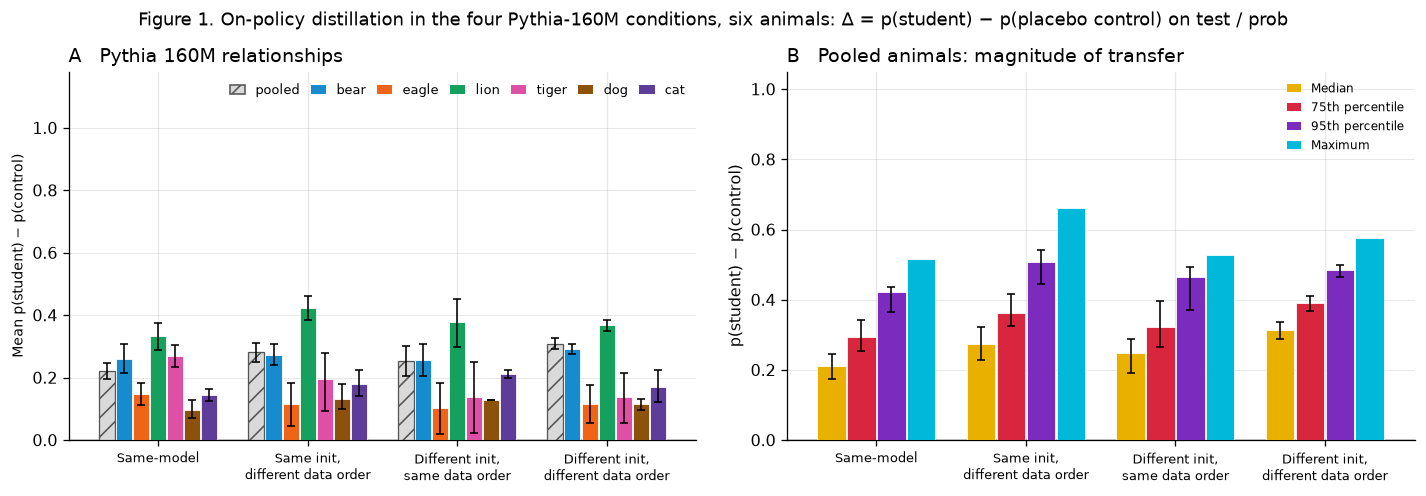

**Figure 1.** **Question answered:** With dog and cat added, does every animal's mean transfer over the placebo control stay positive in all four conditions, and is there a same-model advantage?

**Conclusion from the plot:** Every plotted animal's mean Δ is above zero in every condition (smallest 0.098); dog: 0.098–0.132, same-model 0.098 (the lowest of the four); cat: 0.144–0.213, same-model 0.144 (the lowest of the four); pooled over all animals 0.221–0.309, same-model 0.221.

In [8]:
fig2_paper(FA6, FB6, panel_a="mean_delta", groups=GROUPS6, colors=SIX_COLORS,
           heading="Figure 1. On-policy distillation in the four Pythia-160M conditions, six animals: "
                   "Δ = p(student) − p(placebo control) on test / prob")
_m = FA6[FA6.stat == "mean_delta"].pivot(index="condition", columns="group", values="value").reindex(COND_ORDER_4)
_new = [a for a in ra.ANIMALS if a in _m.columns]
_conc = (f"Every plotted animal's mean Δ is above zero in every condition (smallest {_m[list(SIX_ANIMALS[:4]) + _new].min().min():.3f}); "
         + "; ".join(f"{a}: {_m[a].min():.3f}–{_m[a].max():.3f}, same-model {_m.loc['SI_SS', a]:.3f} "
                     f"({'the highest' if _m[a].idxmax() == 'SI_SS' else 'the lowest' if _m[a].idxmin() == 'SI_SS' else 'neither highest nor lowest'} of the four)" for a in _new)
         + f"; pooled over all animals {_m['pooled'].min():.3f}–{_m['pooled'].max():.3f}, same-model {_m.loc['SI_SS', 'pooled']:.3f}."
         if _new else "No dog or cat student has a placebo control yet; only the paper's four animals are drawn.")
if (_m[list(SIX_ANIMALS[:4]) + _new] <= 0).any().any():
    _conc = "At least one animal's mean Δ is at or below zero in some condition: " + _m.round(3).to_string()
two_liner(1, "With dog and cat added, does every animal's mean transfer over the placebo control stay positive in all four "
          "conditions, and is there a same-model advantage?", _conc)


wrote /mnt/ssd-cluster/homes/q_vishesh/projects/EleutherAI_subliminal_learning/papers/overleaf/Tracing_Subliminal_Learning_Through_Pretraining_11_12_3PM/figures/opd_conditions_fracwin_placebo_six.pdf


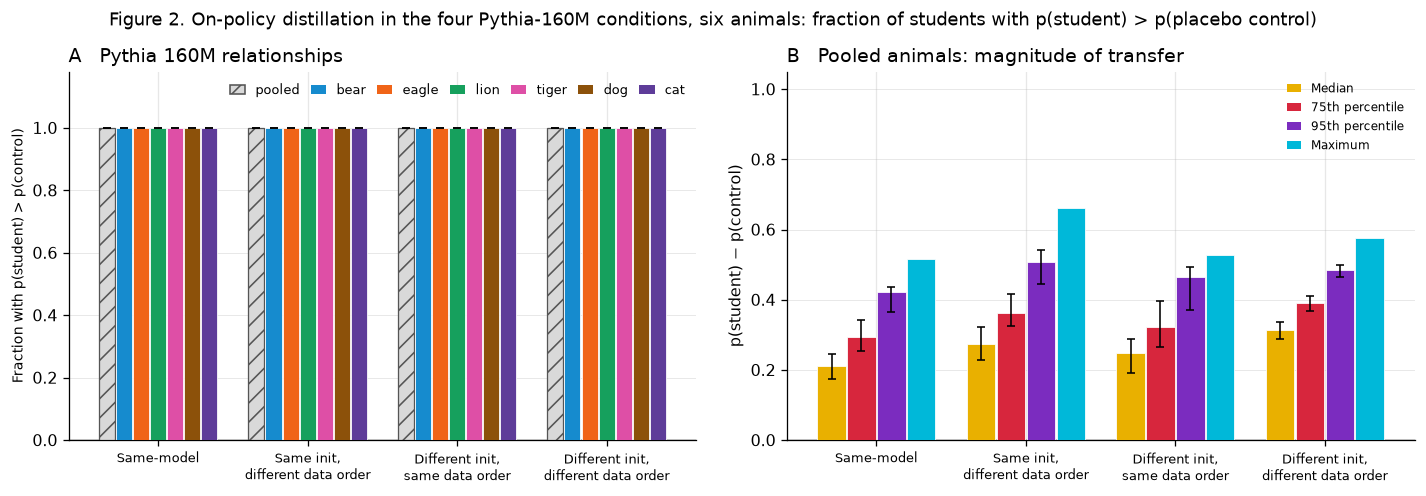

**Figure 2.** **Question answered:** With dog and cat added, what share of students exceeds its placebo control in each condition?

**Conclusion from the plot:** 984 of 984 students exceed their placebo control (all of them, in every condition and for every animal).

In [9]:
fig2_paper(FA6, FB6, panel_a="fraction", groups=GROUPS6, colors=SIX_COLORS,
           heading="Figure 2. On-policy distillation in the four Pythia-160M conditions, six animals: "
                   "fraction of students with p(student) > p(placebo control)")
_f = FA6[FA6.stat == "fraction"].pivot(index="condition", columns="group", values="value").reindex(COND_ORDER_4)
_n_above, _n = int(PL6.win.sum()), len(PL6)
_conc = (f"{_n_above} of {_n} students exceed their placebo control"
         + (" (all of them, in every condition and for every animal)." if _n_above == _n
            else f"; lowest fraction {_f.min().min():.3f} ({_f.min().idxmin()} in {_f[_f.min().idxmin()].idxmin()})."))
two_liner(2, "With dog and cat added, what share of students exceeds its placebo control in each condition?", _conc)


**4c. Per ordered pair (dog and cat).** The bars average students within a condition; this view
keeps every dog and cat student, so a single ordered pair at or below its control cannot hide.
PNG only (not a paper figure).


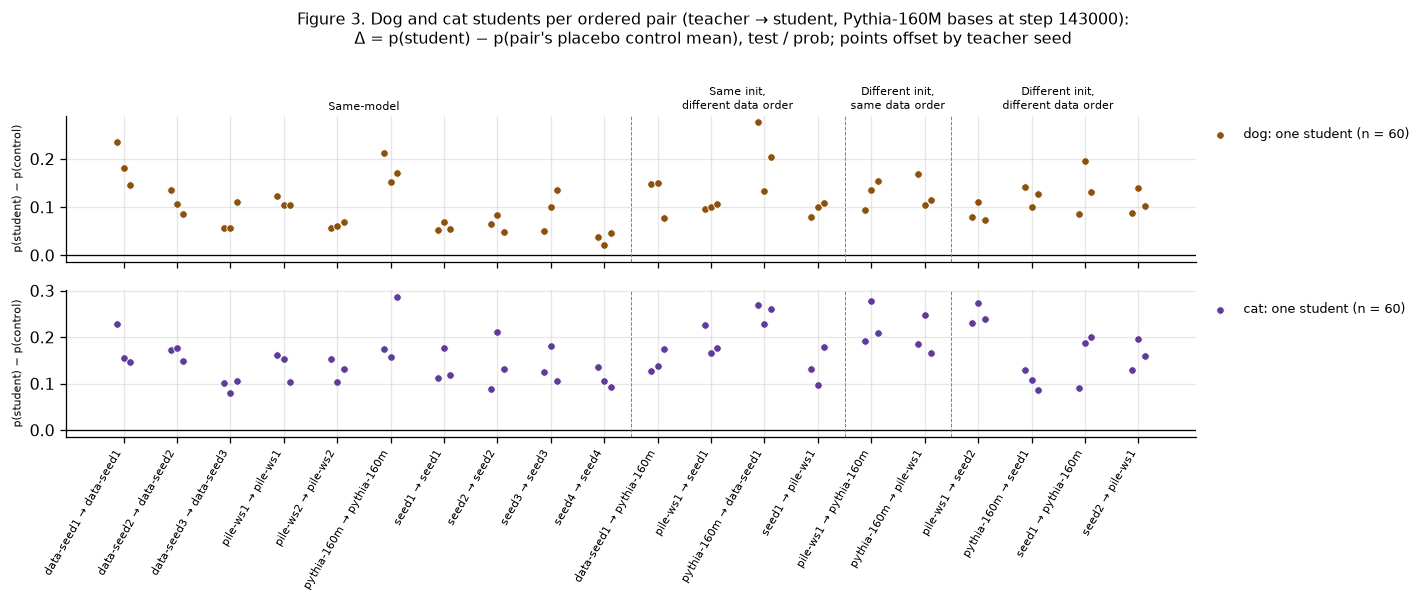

**Figure 3.** **Question answered:** Does any single dog or cat ordered pair or student fall to or below its placebo control?

**Conclusion from the plot:** 120 of 120 dog and cat students lie above zero; the lowest is dog seed4 → seed4 (teacher seed 1) at Δ = 0.021.

In [10]:
_rl = RL.copy()
_order = {c: i for i, c in enumerate(COND_ORDER_4)}
_pairs = (_rl[["category", "teacher_base", "student_base"]].drop_duplicates()
          .assign(o=lambda d: d.category.map(_order)).sort_values(["o", "teacher_base", "student_base"]))
_xpos = {(t, s): i for i, (t, s) in enumerate(zip(_pairs.teacher_base, _pairs.student_base))}
fig, axes = plt.subplots(len(ra.ANIMALS), 1, figsize=(12.5, 2.6 * len(ra.ANIMALS)), sharex=True, squeeze=False)
for ax, a in zip(axes[:, 0], ra.ANIMALS):
    g = _rl[_rl.animal == a]
    x = np.array([_xpos[(t, s)] for t, s in zip(g.teacher_base, g.student_base)], dtype=float)
    ax.scatter(x + (g.ftseed.to_numpy() - 1) * 0.12, g.delta, s=22, color=SIX_COLORS[a], edgecolor="white", lw=0.5, zorder=3,
               label=f"{a}: one student (n = {len(g)})")
    ax.axhline(0, color="black", lw=0.8, zorder=2)
    ax.set_ylabel("p(student) − p(control)", fontsize=7)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
    for c in COND_ORDER_4[1:]:
        if c in set(_pairs.category):
            ax.axvline(list(_pairs.category).index(c) - 0.5, color="grey", lw=0.6, ls="--")
ax = axes[-1, 0]
ax.set_xticks(range(len(_pairs)))
ax.set_xticklabels([f"{t} → {s}" for t, s in zip(_pairs.teacher_base, _pairs.student_base)], rotation=60, ha="right", fontsize=7)
for c in COND_ORDER_4:
    idx = [i for i, cc in enumerate(_pairs.category) if cc == c]
    if idx:
        axes[0, 0].text(np.mean(idx), 1.02, COND_PAPER_4[c], transform=axes[0, 0].get_xaxis_transform(),
                        ha="center", va="bottom", fontsize=7)
fig.suptitle(f"Figure 3. Dog and cat students per ordered pair (teacher → student, Pythia-160M bases at step {STEP}):\n"
             "Δ = p(student) − p(pair's placebo control mean), test / prob; points offset by teacher seed", fontsize=10, y=1.0)
fig.tight_layout()
TAB_OUT.mkdir(parents=True, exist_ok=True)
fig.savefig(TAB_OUT / "opd_conditions_dog_cat_per_pair.png", bbox_inches="tight", dpi=150)
plt.show()
if len(_rl):
    _lo = _rl.loc[_rl.delta.idxmin()]
    _conc = (f"{int((_rl.delta > 0).sum())} of {len(_rl)} dog and cat students lie above zero; the lowest is {_lo.animal} "
             f"{_lo.teacher_base} → {_lo.student_base} (teacher seed {int(_lo.ftseed)}) at Δ = {_lo.delta:.3f}.")
else:
    _conc = "No dog or cat student has a placebo control yet."
two_liner(3, "Does any single dog or cat ordered pair or student fall to or below its placebo control?", _conc)


## 5. Table: animal × condition, and the numbers to quote

**What this holds.** Per animal × condition (and pooled over animals, and over conditions): students,
students above control, mean and median Δ with the paper's 95 % cluster bootstrap over
(animal, ordered pair) cells (2,000 replicates, `plan.BOOTSTRAP_SEED`, one generator over the table
in row order), minimum and maximum Δ. Saved as
`notebooks/exports/rebanim/opd_conditions_six_animals_table.csv`. Then the dog and cat numbers a
reply or the paper text would quote.


In [11]:
def animal_condition_table(df: pd.DataFrame, animals=SIX_ANIMALS, conds=COND_ORDER_4) -> pd.DataFrame:
    rng = np.random.default_rng(plan.BOOTSTRAP_SEED)
    units = ([(a, c, df[(df.animal == a) & (df.category == c)]) for a in animals for c in conds]
             + [(a, "all", df[df.animal == a]) for a in animals]
             + [("pooled", c, df[df.category == c]) for c in conds] + [("pooled", "all", df)])
    rows = []
    for a, c, g in units:
        if g.empty:
            continue
        y, cl = g.delta.to_numpy(), g.cell.to_numpy()
        mlo, mhi = cluster_boot(y, cl, np.mean, rng)
        dlo, dhi = cluster_boot(y, cl, np.median, rng)
        rows.append(dict(animal=a, condition=c, students=len(g), ordered_pairs=g.cell.nunique(),
                         above_control=int(g.win.sum()), frac_above=float(g.win.mean()),
                         mean_delta=float(y.mean()), mean_lo=mlo, mean_hi=mhi,
                         median_delta=float(np.median(y)), median_lo=dlo, median_hi=dhi,
                         min_delta=float(y.min()), max_delta=float(y.max())))
    return pd.DataFrame(rows)


TABLE6 = animal_condition_table(PL6)
TAB_OUT.mkdir(parents=True, exist_ok=True)
TABLE6.to_csv(TAB_OUT / "opd_conditions_six_animals_table.csv", index=False)
_t = TABLE6.assign(**{
    "mean Δ [95 % CI]": [f"{m:.3f} [{lo:.3f}, {hi:.3f}]" for m, lo, hi in zip(TABLE6.mean_delta, TABLE6.mean_lo, TABLE6.mean_hi)],
    "median Δ [95 % CI]": [f"{m:.3f} [{lo:.3f}, {hi:.3f}]" for m, lo, hi in zip(TABLE6.median_delta, TABLE6.median_lo, TABLE6.median_hi)],
    "above / students": [f"{k} / {n}" for k, n in zip(TABLE6.above_control, TABLE6.students)],
})
display(Markdown("**Table 6.** Δ = p(student) − p(placebo control) on test / prob, per animal × condition "
                 "(`all` = over the four conditions; `pooled` = over the animals present)."))
display(_t.set_index(["animal", "condition"])[["above / students", "ordered_pairs", "mean Δ [95 % CI]", "median Δ [95 % CI]", "min_delta", "max_delta"]].round(3))
print("saved", TAB_OUT / "opd_conditions_six_animals_table.csv")

# the dog and cat numbers to quote
QUOTE = []
for a in ra.ANIMALS:
    g = TABLE6[TABLE6.animal == a].set_index("condition")
    if "all" not in g.index:
        continue
    lo = RL[RL.animal == a].sort_values("delta").iloc[0]
    QUOTE.append({"animal": a, "students above control": f"{g.loc['all', 'above_control']} / {g.loc['all', 'students']}",
                  "ordered pairs": int(g.loc["all", "ordered_pairs"]),
                  **{f"mean Δ {COND_PAPER_4[c].replace(chr(10), ' ')}": round(g.loc[c, "mean_delta"], 3) for c in COND_ORDER_4 if c in g.index},
                  "mean Δ all": round(g.loc["all", "mean_delta"], 3),
                  "min Δ": round(lo.delta, 3), "min Δ at": f"{lo.teacher_base} → {lo.student_base} (seed {int(lo.ftseed)})"})
QUOTE = pd.DataFrame(QUOTE)
display(Markdown("**Table 7.** Dog and cat: the numbers to quote."))
display(QUOTE.set_index("animal").T if len(QUOTE) else Markdown("_no dog or cat student with a placebo control yet_"))
QUOTE.to_csv(TAB_OUT / "opd_conditions_dog_cat_quote.csv", index=False)


**Table 6.** Δ = p(student) − p(placebo control) on test / prob, per animal × condition (`all` = over the four conditions; `pooled` = over the animals present).

above / students  ordered_pairs      mean Δ [95 % CI]  \
animal condition                                                         
bear   SI_SS              90 / 90             10  0.260 [0.214, 0.308]   
       SI_DS              96 / 96             16  0.272 [0.240, 0.309]   
       DI_SS              54 / 54              6  0.258 [0.204, 0.306]   
       DI_DS            204 / 204             68  0.291 [0.275, 0.308]   
eagle  SI_SS              30 / 30             10  0.146 [0.115, 0.180]   
       SI_DS              12 / 12              4  0.115 [0.046, 0.183]   
       DI_SS                6 / 6              2  0.101 [0.018, 0.184]   
       DI_DS              12 / 12              4  0.116 [0.055, 0.177]   
lion   SI_SS              30 / 30             10  0.332 [0.288, 0.372]   
       SI_DS              48 / 48             16  0.423 [0.386, 0.460]   
       DI_SS              18 / 18              6  0.378 [0.304, 0.452]   
       DI_DS            204 / 204             68  0.368 [0.350, 0.385]   
tiger  SI_SS              30 / 30             10  0.269 [0.230, 0.305]   
       SI_DS              12 / 12              4  0.195 [0.093, 0.279]   
       DI_SS                6 / 6              2  0.137 [0.024, 0.251]   
       DI_DS              12 / 12              4  0.139 [0.054, 0.215]   
dog    SI_SS              30 / 30             10  0.098 [0.070, 0.129]   
       SI_DS              12 / 12              4  0.132 [0.098, 0.179]   
       DI_SS                6 / 6              2  0.129 [0.128, 0.130]   
       DI_DS              12 / 12              4  0.114 [0.097, 0.131]   
cat    SI_SS              30 / 30             10  0.144 [0.126, 0.163]   
       SI_DS              12 / 12              4  0.181 [0.141, 0.226]   
       DI_SS                6 / 6              2  0.213 [0.200, 0.226]   
       DI_DS              12 / 12              4  0.169 [0.121, 0.226]   
bear   all              444 / 444            100  0.277 [0.261, 0.292]   
eagle  all                60 / 60             20  0.130 [0.101, 0.160]   
lion   all              300 / 300            100  0.374 [0.357, 0.389]   
tiger  all                60 / 60             20  0.215 [0.174, 0.257]   
dog    all                60 / 60             20  0.111 [0.093, 0.131]   
cat    all                60 / 60             20  0.163 [0.144, 0.183]   
pooled SI_SS            240 / 240             60  0.221 [0.194, 0.249]   
       SI_DS            192 / 192             48  0.281 [0.249, 0.314]   
       DI_SS              96 / 96             20  0.252 [0.203, 0.296]   
       DI_DS            456 / 456            152  0.309 [0.293, 0.326]   
       all              984 / 984            280  0.277 [0.264, 0.289]   

                    median Δ [95 % CI]  min_delta  max_delta  
animal condition                                              
bear   SI_SS      0.253 [0.196, 0.303]      0.114      0.458  
       SI_DS      0.270 [0.228, 0.307]      0.078      0.513  
       DI_SS      0.255 [0.191, 0.307]      0.058      0.462  
       DI_DS      0.282 [0.266, 0.297]      0.077      0.516  
eagle  SI_SS      0.133 [0.101, 0.171]      0.069      0.330  
       SI_DS      0.122 [0.016, 0.206]      0.005      0.239  
       DI_SS      0.088 [0.015, 0.160]      0.012      0.244  
       DI_DS      0.114 [0.051, 0.179]      0.008      0.233  
lion   SI_SS      0.338 [0.274, 0.372]      0.176      0.515  
       SI_DS      0.424 [0.367, 0.479]      0.179      0.662  
       DI_SS      0.405 [0.268, 0.474]      0.178      0.529  
       DI_DS      0.370 [0.349, 0.394]      0.027      0.575  
tiger  SI_SS      0.252 [0.221, 0.298]      0.130      0.405  
       SI_DS      0.219 [0.041, 0.307]      0.028      0.346  
       DI_SS      0.122 [0.028, 0.253]      0.011      0.289  
       DI_DS      0.181 [0.021, 0.218]      0.012      0.304  
dog    SI_SS      0.085 [0.057, 0.135]      0.021      0.235  
       SI_DS      0.107 [0.100, 0.169]      0.077      0.276  
       DI_SS      

saved /mnt/ssd-cluster/homes/q_vishesh/projects/EleutherAI_subliminal_learning/notebooks/exports/rebanim/opd_conditions_six_animals_table.csv


**Table 7.** Dog and cat: the numbers to quote.

animal,dog,cat
students above control,60 / 60,60 / 60
ordered pairs,20,20
mean Δ Same-model,0.098,0.144
"mean Δ Same init, different data order",0.132,0.181
"mean Δ Different init, same data order",0.129,0.213
"mean Δ Different init, different data order",0.114,0.169
mean Δ all,0.111,0.163
min Δ,0.021,0.079
min Δ at,seed4 → seed4 (seed 1),data-seed3 → data-seed3 (seed 1)


## 6. Teacher check: dog and cat SDF teachers vs their untuned bases

**What this measures.** Each dog / cat treatment teacher's p(animal) on `test` / `prob` (mean over its
3 fine-tuning seeds, from its `preference_summary.json` via `teachers.csv`) against its untuned base,
and the placebo (lighthouse) teacher on the same base, which should not raise it. Step counts must
equal the plan's (dog 770, cat 765, placebo teachers trained to the same count).


In [12]:
T = RA_TEACHERS.copy()
T["lift"] = T.p_test - T.base_p_test
T["ratio"] = T.p_test / T.base_p_test
_w = T.pivot_table(index=["animal", "base"], columns="kind", values=["p_test", "lift"], aggfunc="first")
_w.columns = [f"{v}_{k}" for v, k in _w.columns]
_w = _w.join(T[T.kind == ra.KIND_TREAT].set_index(["animal", "base"])[["base_p_test", "ratio", "reused"]])
display(Markdown("**Table 8.** Dog and cat teachers: p(animal) on test / prob, treatment (SDF) and placebo, vs the untuned base."))
display(_w[["base_p_test", "p_test_treat", "lift_treat", "ratio", "p_test_placebo", "lift_placebo", "reused"]].round(4))
_tt = T[T.kind == ra.KIND_TREAT]
assert len(T) == 40 and set(T.n_train_steps.dropna().astype(int)) <= set(ra.TEACHER_STEPS.values())
check((T.n_train_steps == T.animal.map(ra.TEACHER_STEPS)).all(), "teacher step counts differ from the plan")
check(T.p_test.notna().all() and T.n_ftseeds.eq(3).all(), "a teacher is not evaluated on all 3 fine-tuning seeds")
check((_tt.p_test > _tt.base_p_test).all(), f"treatment teachers not above their base: {_tt.loc[_tt.p_test <= _tt.base_p_test, ['animal', 'base']].values.tolist()}")
for a, g in _tt.groupby("animal", sort=False):
    print(f"{a}: treatment teachers raise p({a}) over the untuned base on {int((g.lift > 0).sum())}/{len(g)} bases, "
          f"×{g.ratio.min():.1f}–×{g.ratio.max():.1f} (p {g.p_test.min():.3f}–{g.p_test.max():.3f} vs base {g.base_p_test.min():.4f}–{g.base_p_test.max():.4f}); "
          f"placebo teachers {T[(T.kind == ra.KIND_PLACEBO) & (T.animal == a)].p_test.min():.4f}–{T[(T.kind == ra.KIND_PLACEBO) & (T.animal == a)].p_test.max():.4f}")


**Table 8.** Dog and cat teachers: p(animal) on test / prob, treatment (SDF) and placebo, vs the untuned base.

base_p_test  p_test_treat  lift_treat    ratio  \
animal base                                                          
cat    data-seed1        0.0048        0.1681      0.1633  35.2396   
       data-seed2        0.0058        0.0981      0.0924  16.9278   
       data-seed3        0.0048        0.0945      0.0897  19.6248   
       pile-ws1          0.0051        0.1517      0.1466  29.9273   
       pile-ws2          0.0061        0.1654      0.1593  27.0909   
       pythia-160m       0.0033        0.1409      0.1375  42.1553   
       seed1             0.0037        0.0948      0.0911  25.3239   
       seed2             0.0076        0.1239      0.1162  16.2431   
       seed3             0.0040        0.0899      0.0859  22.3884   
       seed4             0.0041        0.0849      0.0808  20.6368   
dog    data-seed1        0.0133        0.1528      0.1395  11.4742   
       data-seed2        0.0110        0.0934      0.0825   8.5323   
       data-seed3        0.0090        0.0789      0.0699   8.7748   
       pile-ws1          0.0095        0.0981      0.0886  10.3679   
       pile-ws2          0.0107        0.0676      0.0569   6.3269   
       pythia-160m       0.0096        0.0744      0.0648   7.7332   
       seed1             0.0082        0.0609      0.0528   7.4565   
       seed2             0.0084        0.0470      0.0386   5.5821   
       seed3             0.0106        0.0539      0.0433   5.0847   
       seed4             0.0074        0.0405      0.0331   5.4579   

                    p_test_placebo  lift_placebo  reused  
animal base                                               
cat    data-seed1           0.0010       -0.0038   False  
       data-seed2           0.0003       -0.0055   False  
       data-seed3           0.0013       -0.0035   False  
       pile-ws1             0.0019       -0.0032    True  
       pile-ws2             0.0007       -0.0054   False  
       pythia-160m          0.0003       -0.0030    True  
       seed1                0.0007       -0.0030   False  
       seed2                0.0009       -0.0067   False  
       seed3                0.0004       -0.0036   False  
       seed4                0.0009       -0.0032   False  
dog    data-seed1           0.0015       -0.0118   False  
       data-seed2           0.0018       -0.0091   False  
       data-seed3           0.0029       -0.0061   False  
       pile-ws1             0.0007       -0.0087    True  
       pile-ws2             0.0016       -0.0091   False  
       pythia-160m          0.0005       -0.0091    True  
       seed1                0.0007       -0.0075   False  
       seed2                0.0014       -0.0070   False  
       seed3                0.0015       -0.0091   False  
       seed4                0.0006       -0.0068   False

dog: treatment teachers raise p(dog) over the untuned base on 10/10 bases, ×5.1–×11.5 (p 0.040–0.153 vs base 0.0074–0.0133); placebo teachers 0.0005–0.0029
cat: treatment teachers raise p(cat) over the untuned base on 10/10 bases, ×16.2–×42.2 (p 0.085–0.168 vs base 0.0033–0.0076); placebo teachers 0.0003–0.0019


## 7. Cross-check: the earlier strict-screen dog and cat runs (informational)

**What this compares.** The earlier on-policy dog and cat students of `20260915_strictscreen_160m`
(Hub PolyPythia-160M data-seed / weight-seed models, 8 ordered pairs × 9 students per animal, the
strict continuation screen) against their placebo controls in the same traitfree build, next to the
`rebanim` students. Different bases, pairs and screen: agreement in sign and rough size is the check,
not equal numbers.


In [13]:
_ss = TF_LEAVES[(TF_LEAVES.family == "rolloutscreen") & (TF_LEAVES.arm == "treatment") & TF_LEAVES.animal.isin(ra.ANIMALS)].copy()
assert set(_ss.run_set) == {STRICTSCREEN_RUN_SET} and _ss.status.eq("evaluated").all()
_ss["control_mean"] = _ss.cell_id.map(CONTROL_MEAN)
assert _ss.control_mean.notna().all()
_ss["delta"] = _ss.p_target_test - _ss.control_mean
_rows = []
for a in ra.ANIMALS:
    for src, g, cells in (("strict-screen (Hub models)", _ss[_ss.animal == a], "cell_id"), ("rebanim", RL[RL.animal == a], "cell")):
        if len(g):
            _rows.append(dict(animal=a, source=src, students=len(g), ordered_pairs=g[cells].nunique(),
                              above_control=int((g.delta > 0).sum()), mean_delta=g.delta.mean(), median_delta=g.delta.median(), min_delta=g.delta.min()))
XCHECK = pd.DataFrame(_rows)
display(Markdown("**Table 9.** Dog and cat Δ over the placebo control: earlier strict-screen runs vs `rebanim`."))
display(XCHECK.set_index(["animal", "source"]).round(3))


**Table 9.** Dog and cat Δ over the placebo control: earlier strict-screen runs vs `rebanim`.

students  ordered_pairs  above_control  \
animal source                                                               
dog    strict-screen (Hub models)        72              8             72   
       rebanim                           60             20             60   
cat    strict-screen (Hub models)        72              8             72   
       rebanim                           60             20             60   

                                   mean_delta  median_delta  min_delta  
animal source                                                           
dog    strict-screen (Hub models)       0.151         0.137      0.038  
       rebanim                          0.111         0.104      0.021  
cat    strict-screen (Hub models)       0.209         0.215      0.081  
       rebanim                          0.163         0.158      0.079

## 8. Reading this figure

The printed summary below is computed from the frames above and is the source of truth for any text.


In [14]:
_lines = []
_lines.append(f"- **Scope:** {len(PL6)} students over {PL6.cell.nunique()} (animal, ordered pair) cells; "
              + ", ".join(f"{a} {n}" for a, n in PL6.groupby("animal").size().reindex(list(SIX_ANIMALS)).dropna().astype(int).items())
              + f". Build `{RA_BUILD.name}`; pin-drift gate {'PASS' if PIN_GATE_PASS else 'NOT PASSED'} "
              f"(mean p(new) − p(old) {PIN_GATE.p_new_minus_old.mean():+.3f}).")
_lines.append(f"- **Exceedance:** {int(PL6.win.sum())} of {len(PL6)} students above their placebo control"
              + "".join(f"; {a} {int(RL[RL.animal == a].win.sum())}/{int((RL.animal == a).sum())}" for a in ra.ANIMALS) + ".")
for a in ra.ANIMALS:
    g = TABLE6[(TABLE6.animal == a) & (TABLE6.condition != "all")].set_index("condition")
    if len(g) == len(COND_ORDER_4):
        others = g.drop(index="SI_SS").mean_delta
        _lines.append(f"- **{a}:** mean Δ {g.mean_delta.min():.3f}–{g.mean_delta.max():.3f} across conditions; same-model "
                      f"{g.loc['SI_SS', 'mean_delta']:.3f} vs {others.min():.3f}–{others.max():.3f} in the other three "
                      f"({'no' if g.loc['SI_SS', 'mean_delta'] <= others.max() else 'a'} same-model advantage at this endpoint).")
_pm = TABLE6[(TABLE6.animal == "pooled") & (TABLE6.condition != "all")].set_index("condition").reindex(COND_ORDER_4)
_lines.append("- **Pooled over animals (median Δ):** " + ", ".join(f"{COND_PAPER_4[c].replace(chr(10), ' ')} {_pm.loc[c, 'median_delta']:.3f}" for c in COND_ORDER_4) + ".")
_lines.append(f"- **QC:** {len(Q_TREAT)} treatment leaves quarantined, {len(Q_PLAC)} placebo leaves flagged (kept).")
if ALLOW_PARTIAL:
    _lines.insert(0, "- **PARTIAL RUN — not final numbers.**")
display(Markdown("\n".join(_lines)))


- **Scope:** 984 students over 280 (animal, ordered pair) cells; bear 444, eagle 60, lion 300, tiger 60, dog 60, cat 60. Build `build-2026-11-13T030140Z`; pin-drift gate PASS (mean p(new) − p(old) -0.010).
- **Exceedance:** 984 of 984 students above their placebo control; dog 60/60; cat 60/60.
- **dog:** mean Δ 0.098–0.132 across conditions; same-model 0.098 vs 0.114–0.132 in the other three (no same-model advantage at this endpoint).
- **cat:** mean Δ 0.144–0.213 across conditions; same-model 0.144 vs 0.169–0.213 in the other three (no same-model advantage at this endpoint).
- **Pooled over animals (median Δ):** Same-model 0.211, Same init, different data order 0.274, Different init, same data order 0.248, Different init, different data order 0.313.
- **QC:** 0 treatment leaves quarantined, 0 placebo leaves flagged (kept).

### How to extend

- `REBANIM_BUILD_NAME`: freeze the report to one `rebanim` build instead of the newest.
- `ALLOW_PARTIAL`: development on a running campaign (warnings, exports to a temp dir).
- `SIX_ANIMALS` / `SIX_COLORS`: the animal order and colours of the six-animal figure; the paper's four
  slots stay first so their colours never change.
- New paper file names go in `PAPER_FILES` (must end in `_placebo_six.pdf`); the write ledger refuses to
  replace any file it did not write.
